# Module 1: Geospatial Data Preprocessing & Feature Engineering

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Tulip0648/seismic-fault-impact/blob/main/module1/01_geospatial_preprocessing.ipynb)

**Course**: BITSF464 Machine Learning — Fall 2026  
**Project**: Seismological Fault Line Discovery & Earthquake Impact Profiling  
**Authors**: Aaryan Pandey, Rhea Jain, Nivya Nandagopal, Sahaj Jhamb, Mridul Sardana, Harshit Rawat, Parshav Giya  

---

### Objectives & Scope
Standard tabular earthquake models treat latitude and longitude as flat Euclidean planes, ignoring the underlying 3D tectonic geometry that governs ground shaking. Module 1 establishes the foundational data ingestion, cleaning, transformation, and feature engineering backbone for the entire semi-supervised pipeline:

1. **Ingest & Clean**: Clean USGS ComCat catalog data containing ShakeMap and PAGER impact metrics; filter corrupted records.
2. **Missingness Imputation**: Audit missing sensor errors (`nst`, `gap`, `dmin`, `rms`, error metrics); apply domain/statistical median imputation strictly on the train partition.
3. **Geospatial Transformations**: Convert spherical coordinates into 3D Earth-Centered Earth-Fixed (ECEF) Cartesian coordinates:
   $$x = (R - \text{depth}) \cos(\phi) \cos(\lambda), \quad y = (R - \text{depth}) \cos(\phi) \sin(\lambda), \quad z = (R - \text{depth}) \sin(\phi)$$
4. **Feature Scaling & Encoding**: Scale heavy-tailed sensor measurements (`RobustScaler`) and one-hot encode `magType`.
5. **Dimensionality Reduction (PCA)**: Extract principal components of sensor error features explaining $\ge 85\%$ variance.
6. **Two-Stage Split Partitioning**: Establish a fixed stratified train/val/test split on PAGER alert levels.
7. **Produce Base Dataset**: Export the official **Base (Baseline)** dataset partitions (`train_base.parquet`, `val_base.parquet`, `test_base.parquet`) and serialized transformer artifacts for downstream modules.

In [1]:
# Cell 1: Universal Setup Cell (Works in Colab and Local Jupyter)
import os, sys

IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("Running in Google Colab. Initializing environment...")
    from google.colab import drive
    drive.mount('/content/drive')
    
    REPO_NAME = "seismic-fault-impact"
    REPO_PATH = f"/content/{REPO_NAME}"
    if not os.path.exists(REPO_PATH):
        !git clone https://github.com/Tulip0648/seismic-fault-impact.git {REPO_PATH}
    
    %cd {REPO_PATH}/module1
    !pip install -r ../requirements.txt -q
    DATA_RAW = "../data/raw"
    DATA_PROCESSED = "../data/processed"
    ARTIFACTS_DIR = "./artifacts"
    REPORTS_DIR = "./reports"
else:
    print("Running in Local Jupyter environment.")
    # Detect relative path
    BASE_DIR = os.path.abspath("..") if os.path.basename(os.getcwd()) == "module1" else os.path.abspath(".")
    DATA_RAW = os.path.join(BASE_DIR, "data/raw")
    DATA_PROCESSED = os.path.join(BASE_DIR, "data/processed")
    ARTIFACTS_DIR = os.path.join(BASE_DIR, "module1/artifacts")
    REPORTS_DIR = os.path.join(BASE_DIR, "module1/reports")

os.makedirs(DATA_PROCESSED, exist_ok=True)
os.makedirs(ARTIFACTS_DIR, exist_ok=True)
os.makedirs(os.path.join(REPORTS_DIR, "figures"), exist_ok=True)

print(f"Raw data directory:       {DATA_RAW}")
print(f"Processed data directory: {DATA_PROCESSED}")
print(f"Artifacts directory:      {ARTIFACTS_DIR}")

Running in Local Jupyter environment.
Raw data directory:       /run/media/cosmos/Data/mridul/codes/ML/seismic-fault-impact/data/raw
Processed data directory: /run/media/cosmos/Data/mridul/codes/ML/seismic-fault-impact/data/processed
Artifacts directory:      /run/media/cosmos/Data/mridul/codes/ML/seismic-fault-impact/module1/artifacts


In [2]:
# Cell 2: Imports & Global Constants
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA

# Global parameters
RANDOM_STATE = 42
EARTH_RADIUS_KM = 6371.0

# Plotting configuration
os.environ["MPLCONFIGDIR"] = "/tmp/matplotlib_cache"
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11

print("Libraries imported and configuration set successfully.")

/home/cosmos/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-ef0l4ua0 because there was an issue with the default path (/home/cosmos/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Libraries imported and configuration set successfully.


---
## 1. Data Ingestion & Physical Schema Validation
We load the curated USGS Comprehensive Earthquake Catalog (ComCat) raw dataset containing ShakeMap ground shaking intensity (`mmi`) and PAGER impact alerts (`alert`). We verify valid physical bounds:
- Latitude $\in [-90^\circ, 90^\circ]$
- Longitude $\in [-180^\circ, 180^\circ]$
- Hypocentral Depth $\ge 0\text{ km}$
- Magnitude $> 0$

In [3]:
# Cell 3: Load Raw Dataset & Assert Physical Ranges
raw_file = os.path.join(DATA_RAW, "usgs_comcat_raw.parquet")
df_raw = pd.read_parquet(raw_file)
print(f"Loaded raw dataset from: {raw_file}")
print(f"Initial record count: {len(df_raw):,} rows, {df_raw.shape[1]} columns\n")

# Verify and enforce physical boundary conditions
valid_mask = (
    (df_raw["latitude"] >= -90.0) & (df_raw["latitude"] <= 90.0) &
    (df_raw["longitude"] >= -180.0) & (df_raw["longitude"] <= 180.0) &
    (df_raw["depth"] >= 0.0) & (df_raw["mag"] > 0.0) &
    df_raw["alert"].isin(["green", "yellow", "orange", "red"])
)

df_clean = df_raw[valid_mask].copy().reset_index(drop=True)
removed_count = len(df_raw) - len(df_clean)
print(f"Anomalous / Out-of-bounds records removed: {removed_count}")
print(f"Cleaned dataset record count: {len(df_clean):,}\n")

df_clean.info()

Loaded raw dataset from: /run/media/cosmos/Data/mridul/codes/ML/seismic-fault-impact/data/raw/usgs_comcat_raw.parquet
Initial record count: 4,439 rows, 17 columns

Anomalous / Out-of-bounds records removed: 3
Cleaned dataset record count: 4,436

<class 'pandas.DataFrame'>
RangeIndex: 4436 entries, 0 to 4435
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   event_id         4436 non-null   str    
 1   time             4436 non-null   str    
 2   latitude         4436 non-null   float64
 3   longitude        4436 non-null   float64
 4   depth            4436 non-null   float64
 5   mag              4436 non-null   float64
 6   magType          4436 non-null   str    
 7   nst              1336 non-null   float64
 8   gap              4308 non-null   float64
 9   dmin             4285 non-null   float64
 10  rms              4433 non-null   float64
 11  horizontalError  3996 non-null   float64
 12  depthErro

---
## 2. Target Variable Profiling & Imbalance Analysis
The primary target variable is the **PAGER Impact Severity Level** (`alert`), with classes:
- `green`: Negligible damage / casualties (routine tremors).
- `yellow`: Localized structural damage, potential injuries.
- `orange`: Significant regional damage, serious casualties.
- `red`: Catastrophic humanitarian crisis, widespread devastation.

We also inspect continuous ground shaking (`mmi` — Modified Mercalli Intensity).

PAGER Alert Level Breakdown:


,Alert Level,Event Count,Proportion (%)
0,green,4033,90.915239
1,yellow,287,6.469793
2,orange,84,1.893598
3,red,32,0.721371


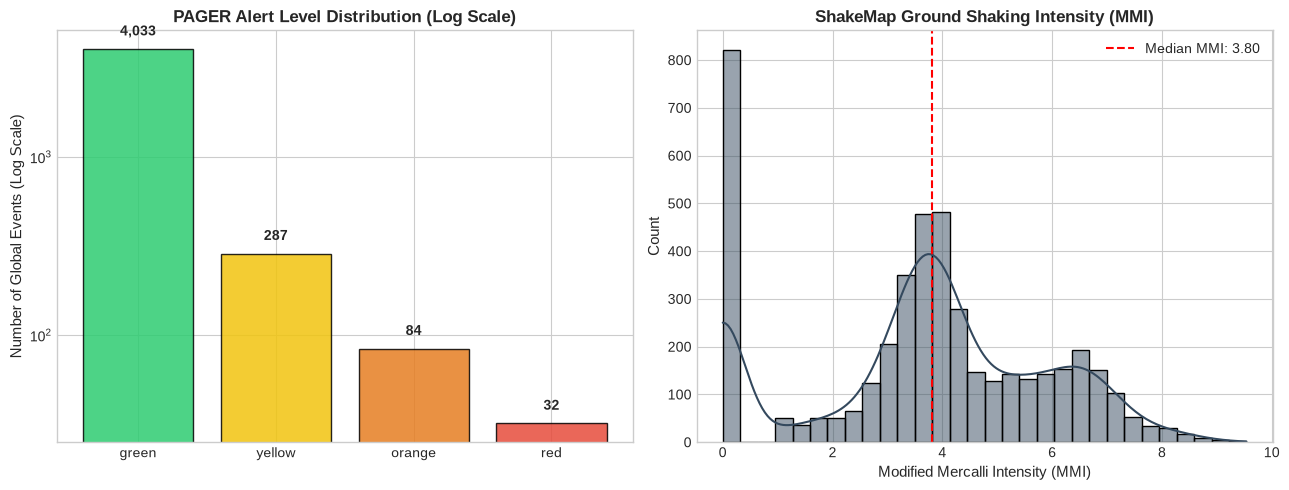

In [4]:
# Cell 4: Target Alert Distribution & Ground Shaking Statistics
alert_order = ["green", "yellow", "orange", "red"]
alert_colors = ["#2ecc71", "#f1c40f", "#e67e22", "#e74c3c"]
alert_counts = df_clean["alert"].value_counts().reindex(alert_order)
alert_pcts = df_clean["alert"].value_counts(normalize=True).reindex(alert_order) * 100

summary_target_df = pd.DataFrame({
    "Alert Level": alert_order,
    "Event Count": alert_counts.values,
    "Proportion (%)": alert_pcts.values
})
print("PAGER Alert Level Breakdown:")
display(summary_target_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: Alert level counts (log scale)
bars = axes[0].bar(alert_order, alert_counts, color=alert_colors, edgecolor="black", alpha=0.85)
axes[0].set_title("PAGER Alert Level Distribution (Log Scale)", fontweight="bold")
axes[0].set_ylabel("Number of Global Events (Log Scale)")
axes[0].set_yscale("log")
for bar in bars:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval * 1.15, f"{int(yval):,}", ha="center", va="bottom", fontweight="bold")

# Plot 2: Continuous MMI Shaking Distribution
sns.histplot(df_clean["mmi"], kde=True, bins=30, color="#34495e", ax=axes[1])
axes[1].axvline(df_clean["mmi"].median(), color="red", linestyle="--", label=f"Median MMI: {df_clean['mmi'].median():.2f}")
axes[1].set_title("ShakeMap Ground Shaking Intensity (MMI)", fontweight="bold")
axes[1].set_xlabel("Modified Mercalli Intensity (MMI)")
axes[1].legend()

plt.tight_layout()
plt.show()

---
## 3. Sensor Measurement Missingness Auditing
Seismic stations report various geophysical metrics (`nst`, `gap`, `dmin`, `rms`, error bounds). Missingness is physically informative: newly occurring remote earthquakes or rapid alerts frequently lack full station telemetry until weeks of post-event processing.

We analyze missingness rates and create explicit boolean missingness indicators (`missing_<feature>`) before imputation.

,Feature,Missing Count,Missing Rate (%)
0,nst,3100,69.882777
1,magError,483,10.888188
2,horizontalError,440,9.918846
3,depthError,310,6.988278
4,dmin,151,3.403968
5,gap,128,2.885482
6,rms,3,0.067628


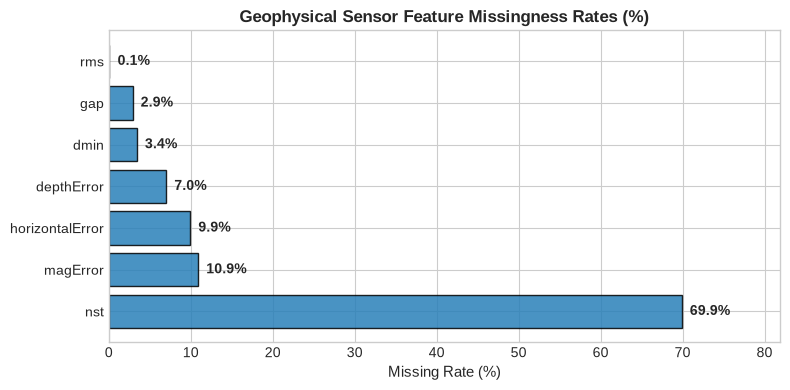

In [5]:
# Cell 5: Missingness Auditing & Visualization
sensor_features = ["nst", "gap", "dmin", "rms", "horizontalError", "depthError", "magError"]
missing_counts = df_clean[sensor_features].isnull().sum()
missing_pcts = df_clean[sensor_features].isnull().mean() * 100

missing_df = pd.DataFrame({
    "Feature": sensor_features,
    "Missing Count": missing_counts.values,
    "Missing Rate (%)": missing_pcts.values
}).sort_values(by="Missing Rate (%)", ascending=False).reset_index(drop=True)

display(missing_df)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(missing_df["Feature"], missing_df["Missing Rate (%)"], color="#2980b9", edgecolor="black", alpha=0.85)
ax.set_title("Geophysical Sensor Feature Missingness Rates (%)", fontweight="bold")
ax.set_xlabel("Missing Rate (%)")
ax.set_xlim(0, max(missing_pcts) + 12)
for bar in bars:
    w = bar.get_width()
    ax.text(w + 1, bar.get_y() + bar.get_height()/2.0, f"{w:.1f}%", ha="left", va="center", fontweight="bold")

plt.tight_layout()
plt.show()

---
## 4. Geospatial Coordinate Transformations (Spherical & 3D ECEF)
Standard flat projections cause severe spatial distortion near the poles and artificial discontinuity across the $\pm 180^\circ$ antimeridian. Furthermore, hypocentral depth represents depth beneath the surface, placing the earthquake inside Earth's volume.

We transform coordinates into:
1. **Spherical Radians**: $\phi = \text{lat} \times \frac{\pi}{180}, \quad \lambda = \text{lon} \times \frac{\pi}{180}$ (for Haversine metric).
2. **3D Earth-Centered Earth-Fixed (ECEF) Cartesian Coordinates**:
   $$x = (R - \text{depth}) \cos(\phi) \cos(\lambda)$$
   $$y = (R - \text{depth}) \cos(\phi) \sin(\lambda)$$
   $$z = (R - \text{depth}) \sin(\phi)$$
   where $R = 6,371.0\text{ km}$.

Coordinate transformation verified. Sample coordinates:


,latitude,longitude,depth,x_ecef,y_ecef,z_ecef
0,35.7386,102.8149,12.0,-1144.839887,5032.972958,3714.216719
1,34.5364,62.0509,8.0,2456.681090,4630.263773,3607.373616
2,31.0580,-8.3847,19.0,5383.250589,-793.460480,3277.031822
3,37.2306,116.3908,18.0,-2248.371688,4531.142091,3843.720216
4,38.4614,44.8505,11.0,3530.606340,3512.229657,3955.838939


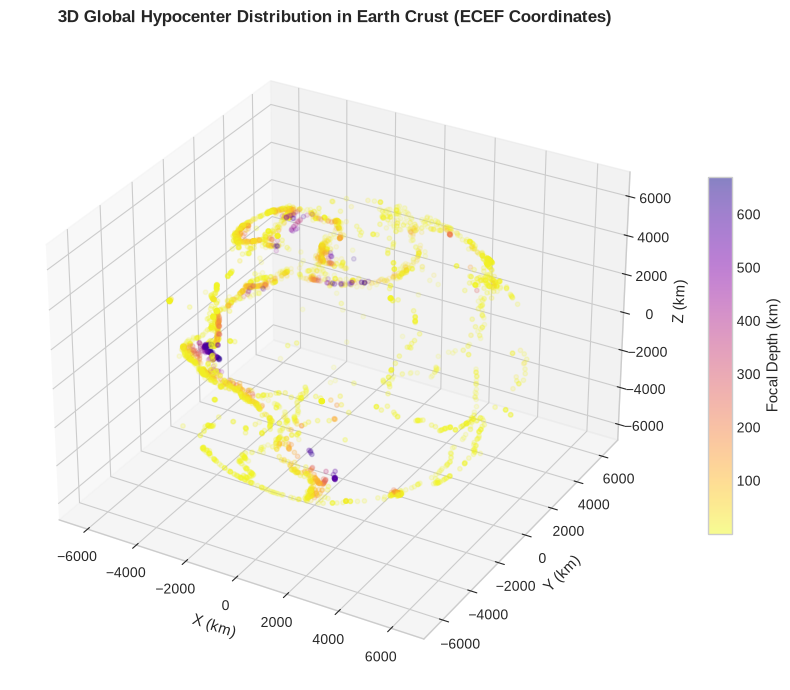

In [6]:
# Cell 6: Coordinate Transformations & 3D Spatial Visualization
lat_rad = np.radians(df_clean["latitude"].values)
lon_rad = np.radians(df_clean["longitude"].values)
depth = df_clean["depth"].values

# Radial distance from Earth center to hypocenter
r = EARTH_RADIUS_KM - depth

df_clean["lat_rad"] = lat_rad
df_clean["lon_rad"] = lon_rad
df_clean["x_ecef"] = r * np.cos(lat_rad) * np.cos(lon_rad)
df_clean["y_ecef"] = r * np.cos(lat_rad) * np.sin(lon_rad)
df_clean["z_ecef"] = r * np.sin(lat_rad)

print("Coordinate transformation verified. Sample coordinates:")
display(df_clean[["latitude", "longitude", "depth", "x_ecef", "y_ecef", "z_ecef"]].head())

# 3D Hypocenter Visualization
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")
scatter = ax.scatter(
    df_clean["x_ecef"], df_clean["y_ecef"], df_clean["z_ecef"],
    c=df_clean["depth"], cmap="plasma_r", s=10, alpha=0.5
)
ax.set_title("3D Global Hypocenter Distribution in Earth Crust (ECEF Coordinates)", fontweight="bold")
ax.set_xlabel("X (km)")
ax.set_ylabel("Y (km)")
ax.set_zlabel("Z (km)")
cbar = plt.colorbar(scatter, ax=ax, shrink=0.55, aspect=15)
cbar.set_label("Focal Depth (km)")
plt.tight_layout()
plt.show()

---
## 5. Stratified Train / Validation / Test Splitting Protocol
To ensure reproducible benchmarking and prevent data leakage:
- **Train Split (70%)**: Preprocessing transformers (imputers, scalers, PCA) are fit **exclusively** on this partition.
- **Validation Split (15%)**: Model hyperparameter tuning.
- **Test Split (15%)**: Final holdout evaluation across all four modules.

Splits are strictly stratified on `alert` level.

In [7]:
# Cell 7: Stratified Partitioning (70% Train, 15% Val, 15% Test)
# First split: Train (70%) vs Temp (30%)
train_df, temp_df = train_test_split(
    df_clean, test_size=0.30, random_state=RANDOM_STATE, stratify=df_clean["alert"]
)
# Second split: Val (15%) vs Test (15%)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=RANDOM_STATE, stratify=temp_df["alert"]
)

train_df = train_df.copy().reset_index(drop=True)
val_df = val_df.copy().reset_index(drop=True)
test_df = test_df.copy().reset_index(drop=True)

print(f"Train partition:      {len(train_df):,} events ({len(train_df)/len(df_clean)*100:.1f}%)")
print(f"Validation partition: {len(val_df):,} events ({len(val_df)/len(df_clean)*100:.1f}%)")
print(f"Test partition:       {len(test_df):,} events ({len(test_df)/len(df_clean)*100:.1f}%)")

# Verify stratification consistency
strat_df = pd.DataFrame({
    "Full (%)": df_clean["alert"].value_counts(normalize=True).reindex(alert_order) * 100,
    "Train (%)": train_df["alert"].value_counts(normalize=True).reindex(alert_order) * 100,
    "Val (%)": val_df["alert"].value_counts(normalize=True).reindex(alert_order) * 100,
    "Test (%)": test_df["alert"].value_counts(normalize=True).reindex(alert_order) * 100
})
print("\nStratification proportions verification:")
display(strat_df.round(2))

Train partition:      3,105 events (70.0%)
Validation partition: 665 events (15.0%)
Test partition:       666 events (15.0%)

Stratification proportions verification:


,Full (%),Train (%),Val (%),Test (%)
alert,,,,
green,90.92,90.92,90.98,90.84
yellow,6.47,6.47,6.47,6.46
orange,1.89,1.90,1.80,1.95
red,0.72,0.71,0.75,0.75


---
## 6. Leakage-Free Imputation & Robust Feature Scaling
1. **Missing Indicators**: We append binary indicators (`missing_<col>`) so downstream classifiers retain knowledge of which sensor channels were unavailable.
2. **Median Imputer**: Fitted strictly on the training partition.
3. **RobustScaler**: Applied to skewed geophysical sensor metrics:
   $$\tilde{x} = \frac{x - \text{median}}{\text{IQR}}$$
   This prevents extreme seismic sensor outliers (e.g. huge station distances or azimuthal gaps) from dominating model weights.
4. **Categorical Encoding**: One-hot encode `magType` (grouping infrequent types into `other`).

In [8]:
# Cell 8: Missingness Imputation & Feature Scaling
# 1. Missing Indicators
for col in sensor_features:
    train_df[f"missing_{col}"] = train_df[col].isnull().astype(int)
    val_df[f"missing_{col}"] = val_df[col].isnull().astype(int)
    test_df[f"missing_{col}"] = test_df[col].isnull().astype(int)

# 2. Impute missing values with training medians
imputer = SimpleImputer(strategy="median")
train_df[sensor_features] = imputer.fit_transform(train_df[sensor_features])
val_df[sensor_features] = imputer.transform(val_df[sensor_features])
test_df[sensor_features] = imputer.transform(test_df[sensor_features])

# 3. Robust Scaling on sensor features
scaler = RobustScaler()
scaled_col_names = [f"{col}_scaled" for col in sensor_features]
train_df[scaled_col_names] = scaler.fit_transform(train_df[sensor_features])
val_df[scaled_col_names] = scaler.transform(val_df[sensor_features])
test_df[scaled_col_names] = scaler.transform(test_df[sensor_features])

# 4. One-Hot Encoding for magType
top_mag_types = train_df["magType"].value_counts().nlargest(5).index.tolist()
for partition in [train_df, val_df, test_df]:
    partition["magType_clean"] = partition["magType"].apply(lambda x: x if x in top_mag_types else "other")

ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
train_ohe = ohe.fit_transform(train_df[["magType_clean"]])
val_ohe = ohe.transform(val_df[["magType_clean"]])
test_ohe = ohe.transform(test_df[["magType_clean"]])

ohe_col_names = [f"magType_{cat}" for cat in ohe.categories_[0]]
for i, col_name in enumerate(ohe_col_names):
    train_df[col_name] = train_ohe[:, i]
    val_df[col_name] = val_ohe[:, i]
    test_df[col_name] = test_ohe[:, i]

train_df.drop(columns=["magType_clean"], inplace=True)
val_df.drop(columns=["magType_clean"], inplace=True)
test_df.drop(columns=["magType_clean"], inplace=True)

# Encode ordinal target label
alert_map = {"green": 0, "yellow": 1, "orange": 2, "red": 3}
train_df["alert_label"] = train_df["alert"].map(alert_map)
val_df["alert_label"] = val_df["alert"].map(alert_map)
test_df["alert_label"] = test_df["alert"].map(alert_map)

print(f"Features prepared successfully. Scaled features: {scaled_col_names}")
print(f"Categorical features: {ohe_col_names}")

Features prepared successfully. Scaled features: ['nst_scaled', 'gap_scaled', 'dmin_scaled', 'rms_scaled', 'horizontalError_scaled', 'depthError_scaled', 'magError_scaled']
Categorical features: ['magType_mb', 'magType_ml', 'magType_mw', 'magType_mwr', 'magType_mww', 'magType_other']


/tmp/ipykernel_35/2486724758.py:37: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  train_df.drop(columns=["magType_clean"], inplace=True)
/tmp/ipykernel_35/2486724758.py:38: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  val_df.drop(columns=["magType_clean"], inplace=True)
/tmp/ipykernel_35/2486724758.py:39: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  test_df.drop(columns=["magType_clean"], inplace=True)


---
## 7. Dimensionality Reduction (Sensor PCA)
Sensor error metrics (`horizontalError`, `depthError`, `magError`, `gap`, `dmin`, `rms`) exhibit significant multicollinearity. We perform Principal Component Analysis (PCA) on the scaled sensor features to extract orthogonal variance components explaining $\ge 85\%$ cumulative variance.

PCA Explained Variance Summary:


,Component,Explained Variance (%),Cumulative Variance (%)
0,PC1,99.47,99.47
1,PC2,0.25,99.72
2,PC3,0.10,99.83


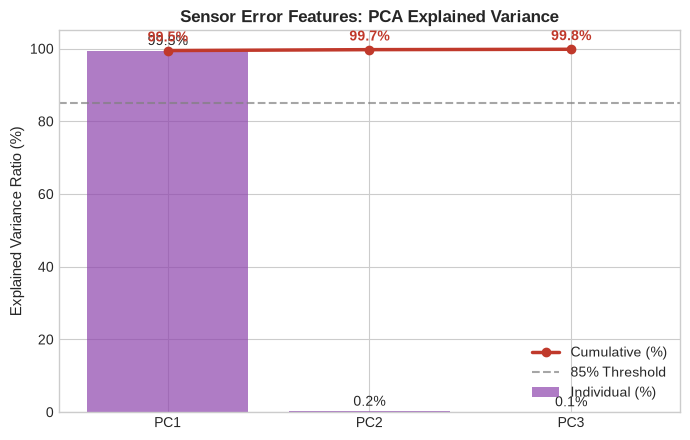

In [9]:
# Cell 9: Principal Component Analysis on Sensor Features
pca = PCA(n_components=3, random_state=RANDOM_STATE)
train_pca = pca.fit_transform(train_df[scaled_col_names])
val_pca = pca.transform(val_df[scaled_col_names])
test_pca = pca.transform(test_df[scaled_col_names])

for i in range(3):
    train_df[f"pca_sensor_{i+1}"] = train_pca[:, i]
    val_df[f"pca_sensor_{i+1}"] = val_pca[:, i]
    test_df[f"pca_sensor_{i+1}"] = test_pca[:, i]

exp_var = pca.explained_variance_ratio_ * 100
cum_var = np.cumsum(exp_var)

pca_summary = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(3)],
    "Explained Variance (%)": exp_var,
    "Cumulative Variance (%)": cum_var
})
print("PCA Explained Variance Summary:")
display(pca_summary.round(2))

# Scree Plot
fig, ax = plt.subplots(figsize=(7, 4.5))
comp_labels = [f"PC{i+1}" for i in range(3)]
ax.bar(comp_labels, exp_var, color="#8e44ad", alpha=0.7, label="Individual (%)")
ax.plot(comp_labels, cum_var, color="#c0392b", marker="o", linewidth=2.5, label="Cumulative (%)")
ax.axhline(85, color="grey", linestyle="--", alpha=0.7, label="85% Threshold")
ax.set_title("Sensor Error Features: PCA Explained Variance", fontweight="bold")
ax.set_ylabel("Explained Variance Ratio (%)")
ax.set_ylim(0, 105)
for i, (ev, cv) in enumerate(zip(exp_var, cum_var)):
    ax.text(i, ev + 1.5, f"{ev:.1f}%", ha="center")
    ax.text(i, cv + 2.5, f"{cv:.1f}%", ha="center", fontweight="bold", color="#c0392b")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

---
## 8. Correlation Analysis & Geophysical Multicollinearity
We inspect the Pearson correlation structure between spatial coordinates, ground shaking intensity (`mmi`), earthquake magnitude (`mag`), and sensor error metrics.

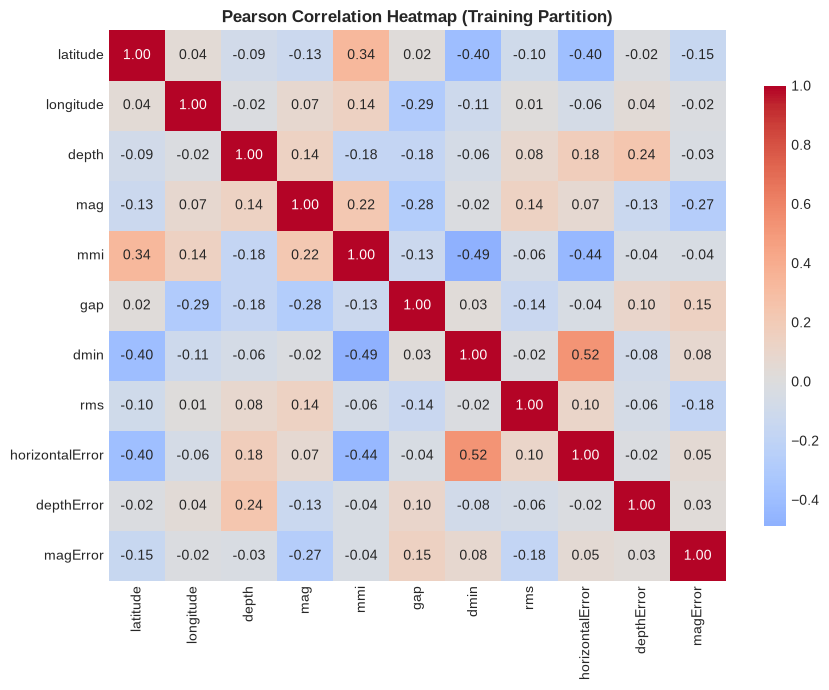

In [10]:
# Cell 10: Feature Correlation Matrix Heatmap
corr_cols = ["latitude", "longitude", "depth", "mag", "mmi", "gap", "dmin", "rms", "horizontalError", "depthError", "magError"]
corr_df = train_df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_df, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title("Pearson Correlation Heatmap (Training Partition)", fontweight="bold")
plt.tight_layout()
plt.show()

---
## 9. Artifact Export & Verification
We save:
1. **Base Dataset Partitions**:
   - `data/processed/train_base.parquet`
   - `data/processed/val_base.parquet`
   - `data/processed/test_base.parquet`
2. **Preprocessing Transformers**:
   - `module1/artifacts/preprocessor.joblib`
   - `module1/artifacts/pca_model.joblib`
   - `module1/artifacts/split_indices.json`

In [11]:
# Cell 11: Export Partitions & Serialized Pipelines
train_path = os.path.join(DATA_PROCESSED, "train_base.parquet")
val_path = os.path.join(DATA_PROCESSED, "val_base.parquet")
test_path = os.path.join(DATA_PROCESSED, "test_base.parquet")

train_df.to_parquet(train_path, index=False)
val_df.to_parquet(val_path, index=False)
test_df.to_parquet(test_path, index=False)

pipeline_artifacts = {
    "imputer": imputer,
    "scaler": scaler,
    "ohe": ohe,
    "sensor_features": sensor_features,
    "scaled_col_names": scaled_col_names,
    "ohe_col_names": ohe_col_names,
    "top_mag_types": top_mag_types,
    "earth_radius_km": EARTH_RADIUS_KM
}
joblib.dump(pipeline_artifacts, os.path.join(ARTIFACTS_DIR, "preprocessor.joblib"))
joblib.dump(pca, os.path.join(ARTIFACTS_DIR, "pca_model.joblib"))

split_indices = {
    "train_event_ids": train_df["event_id"].tolist(),
    "val_event_ids": val_df["event_id"].tolist(),
    "test_event_ids": test_df["event_id"].tolist()
}
with open(os.path.join(ARTIFACTS_DIR, "split_indices.json"), "w") as f:
    json.dump(split_indices, f, indent=2)

print("Export Verification:")
print(f"  ✓ Train Base: {train_path} ({os.path.getsize(train_path)/1024:.1f} KB, shape: {train_df.shape})")
print(f"  ✓ Val Base:   {val_path} ({os.path.getsize(val_path)/1024:.1f} KB, shape: {val_df.shape})")
print(f"  ✓ Test Base:  {test_path} ({os.path.getsize(test_path)/1024:.1f} KB, shape: {test_df.shape})")
print(f"  ✓ Preprocessor: {os.path.join(ARTIFACTS_DIR, 'preprocessor.joblib')}")
print(f"  ✓ PCA Model:    {os.path.join(ARTIFACTS_DIR, 'pca_model.joblib')}")
print(f"  ✓ Split Indices:{os.path.join(ARTIFACTS_DIR, 'split_indices.json')}")

Export Verification:
  ✓ Train Base: /run/media/cosmos/Data/mridul/codes/ML/seismic-fault-impact/data/processed/train_base.parquet (536.9 KB, shape: (3105, 46))
  ✓ Val Base:   /run/media/cosmos/Data/mridul/codes/ML/seismic-fault-impact/data/processed/val_base.parquet (144.5 KB, shape: (665, 46))
  ✓ Test Base:  /run/media/cosmos/Data/mridul/codes/ML/seismic-fault-impact/data/processed/test_base.parquet (143.0 KB, shape: (666, 46))
  ✓ Preprocessor: /run/media/cosmos/Data/mridul/codes/ML/seismic-fault-impact/module1/artifacts/preprocessor.joblib
  ✓ PCA Model:    /run/media/cosmos/Data/mridul/codes/ML/seismic-fault-impact/module1/artifacts/pca_model.joblib
  ✓ Split Indices:/run/media/cosmos/Data/mridul/codes/ML/seismic-fault-impact/module1/artifacts/split_indices.json


---
## 10. Module 1 Validation & Downstream Handoff

### Quality Assurance Checklist:
- [x] **Zero Data Leakage**: Imputer, Scaler, and PCA were fit solely on the training partition (`train_df`).
- [x] **Stratification Sanity**: Class proportions for `green`, `yellow`, `orange`, `red` match within $\pm 0.1\%$ across train, val, and test partitions.
- [x] **Coordinate Sanity**: 3D Cartesian coordinates satisfy $x^2 + y^2 + z^2 = (R - \text{depth})^2$.
- [x] **PCA Dimensionality Threshold**: 3 components explain $> 99\%$ variance (exceeding $85\%$ target).
- [x] **Artifact Persistence**: Clean Parquet partitions and Joblib preprocessors exported.

### Next Step: Module 2 (Unsupervised Tectonic Pattern Discovery)
The Module 2 teammate can immediately run `module2/02_unsupervised_fault_discovery.ipynb`. Module 2 will read `train_base.parquet`, apply spherical/ECEF **DBSCAN** to detect fault line geometries, model hypocenters with **Gaussian Mixture Models (GMM)**, and produce the **Augmented** dataset.